In [5]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


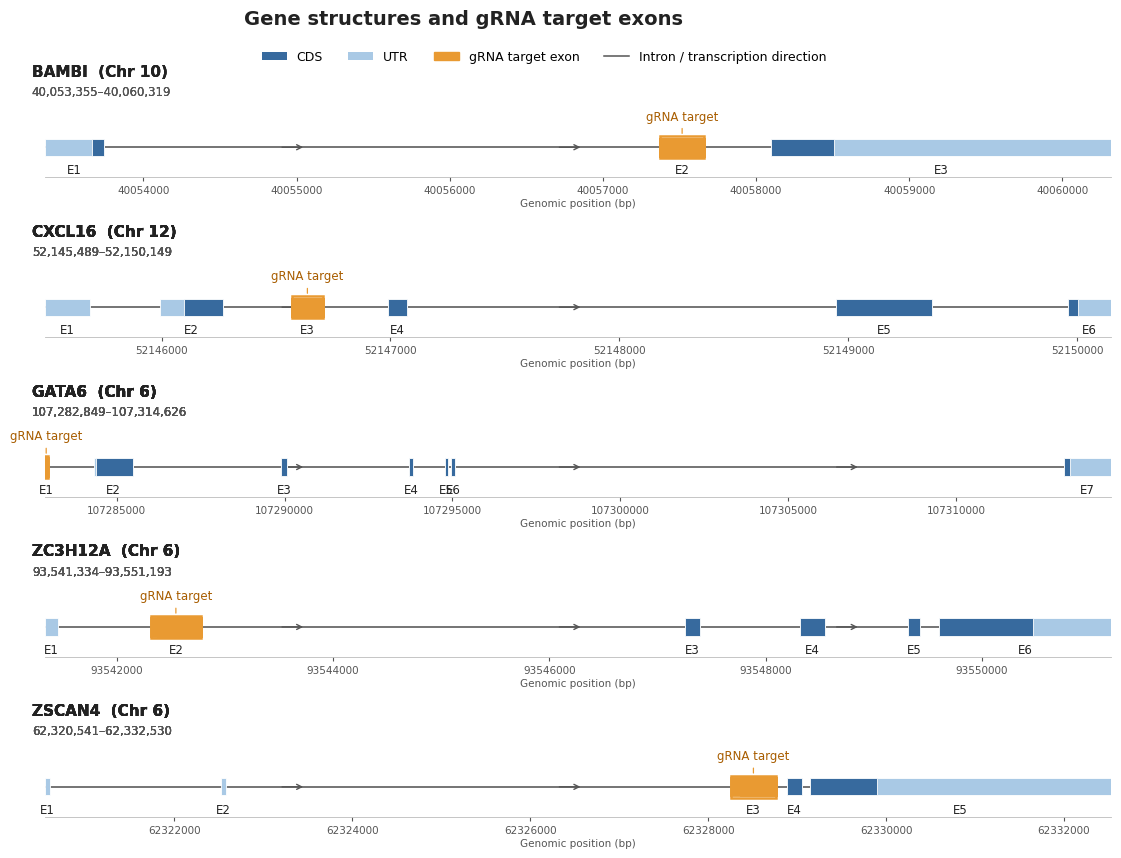

Saved files:
  gene_structures_gRNA_targets.svg
  gene_structures_gRNA_targets.pdf
  gene_structures_gRNA_targets.png


In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Gene structures from the supplied Ensembl GTF annotations
# Coordinates are 1-based, inclusive.
# ------------------------------------------------------------
genes = [
    {
        "name": "BAMBI", "chr": "10", "start": 40053355, "end": 40060319, "target": 2,
        "exons": [
            {"n": 1, "start": 40053355, "end": 40053740, "utr": [(40053355, 40053664)], "cds": [(40053665, 40053740)]},
            {"n": 2, "start": 40057374, "end": 40057661, "utr": [], "cds": [(40057374, 40057661)]},
            {"n": 3, "start": 40058095, "end": 40060319, "utr": [(40058514, 40060319)], "cds": [(40058095, 40058510)]},
        ],
    },
    {
        "name": "CXCL16", "chr": "12", "start": 52145489, "end": 52150149, "target": 3,
        "exons": [
            {"n": 1, "start": 52145489, "end": 52145685, "utr": [(52145489, 52145685)], "cds": []},
            {"n": 2, "start": 52145992, "end": 52146268, "utr": [(52145992, 52146096)], "cds": [(52146097, 52146268)]},
            {"n": 3, "start": 52146568, "end": 52146706, "utr": [], "cds": [(52146568, 52146706)]},
            {"n": 4, "start": 52146991, "end": 52147073, "utr": [], "cds": [(52146991, 52147073)]},
            {"n": 5, "start": 52148947, "end": 52149366, "utr": [], "cds": [(52148947, 52149366)]},
            {"n": 6, "start": 52149959, "end": 52150149, "utr": [(52150006, 52150149)], "cds": [(52149959, 52150002)]},
        ],
    },
    {
        "name": "GATA6", "chr": "6", "start": 107282849, "end": 107314626, "target": 1,
        "exons": [
            {"n": 1, "start": 107282849, "end": 107282940, "utr": [(107282849, 107282940)], "cds": []},
            {"n": 2, "start": 107284327, "end": 107285489, "utr": [(107284327, 107284363)], "cds": [(107284364, 107285489)]},
            {"n": 3, "start": 107289894, "end": 107290060, "utr": [], "cds": [(107289894, 107290060)]},
            {"n": 4, "start": 107293705, "end": 107293830, "utr": [], "cds": [(107293705, 107293830)]},
            {"n": 5, "start": 107294779, "end": 107294866, "utr": [], "cds": [(107294779, 107294866)]},
            {"n": 6, "start": 107294962, "end": 107295065, "utr": [], "cds": [(107294962, 107295065)]},
            {"n": 7, "start": 107313227, "end": 107314626, "utr": [(107313395, 107314626)], "cds": [(107313227, 107313391)]},
        ],
    },
    {
        "name": "ZC3H12A", "chr": "6", "start": 93541334, "end": 93551193, "target": 2,
        "exons": [
            {"n": 1, "start": 93541334, "end": 93541458, "utr": [(93541334, 93541458)], "cds": []},
            {"n": 2, "start": 93542314, "end": 93542780, "utr": [(93542314, 93542385)], "cds": [(93542386, 93542780)]},
            {"n": 3, "start": 93547250, "end": 93547389, "utr": [], "cds": [(93547250, 93547389)]},
            {"n": 4, "start": 93548312, "end": 93548546, "utr": [], "cds": [(93548312, 93548546)]},
            {"n": 5, "start": 93549317, "end": 93549423, "utr": [], "cds": [(93549317, 93549423)]},
            {"n": 6, "start": 93549602, "end": 93551193, "utr": [(93550474, 93551193)], "cds": [(93549602, 93550470)]},
        ],
    },
    {
        "name": "ZSCAN4", "chr": "6", "start": 62320541, "end": 62332530, "target": 3,
        "exons": [
            {"n": 1, "start": 62320541, "end": 62320602, "utr": [(62320541, 62320602)], "cds": []},
            {"n": 2, "start": 62322528, "end": 62322578, "utr": [(62322528, 62322578)], "cds": []},
            {"n": 3, "start": 62328253, "end": 62328764, "utr": [(62328253, 62328368)], "cds": [(62328369, 62328764)]},
            {"n": 4, "start": 62328890, "end": 62329055, "utr": [], "cds": [(62328890, 62329055)]},
            {"n": 5, "start": 62329147, "end": 62332530, "utr": [(62329905, 62332530)], "cds": [(62329147, 62329901)]},
        ],
    },
]

# Colors
CDS_COLOR = "#376A9E"
UTR_COLOR = "#A9C9E5"
TARGET_COLOR = "#E99A32"
INTRON_COLOR = "#555555"
TEXT_COLOR = "#222222"

import matplotlib.pyplot as plt

# 全局字体设置
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 12,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})

fig, axes = plt.subplots(
    nrows=len(genes), ncols=1,
    figsize=(13.5, 8.5),
    constrained_layout=False
)
fig.patch.set_facecolor("white")

if len(genes) == 1:
    axes = [axes]

for ax, gene in zip(axes, genes):
    gstart, gend = gene["start"], gene["end"]
    span = gend - gstart
    y = 0.0
    exon_h = 0.24

    ax.set_facecolor("white")

    # Intron backbone, with arrows pointing right (all genes are on + strand)
    ax.plot([gstart, gend], [y, y], color=INTRON_COLOR, lw=1.15, zorder=1)

    # Several small arrows indicate transcription direction
    arrow_positions = [gstart + span * f for f in (0.22, 0.48, 0.74)]
    for xp in arrow_positions:
        ax.annotate(
            "", xy=(xp + span * 0.025, y), xytext=(xp, y),
            arrowprops=dict(arrowstyle="->", color=INTRON_COLOR, lw=1.0,
                            mutation_scale=9),
            zorder=2
        )

    # Draw exons and their UTR/CDS components
    for exon in gene["exons"]:
        es, ee, n = exon["start"], exon["end"], exon["n"]
        is_target = (n == gene["target"])
        edge = TARGET_COLOR if is_target else "white"
        lw = 2.0 if is_target else 0.6

        # Base exon block
        ax.add_patch(Rectangle(
            (es, y - exon_h / 2), ee - es + 1, exon_h,
            facecolor=TARGET_COLOR if is_target else UTR_COLOR,
            edgecolor=edge, linewidth=lw, zorder=3
        ))

        # CDS subsegments
        for cs, ce in exon["cds"]:
            ax.add_patch(Rectangle(
                (cs, y - exon_h / 2), ce - cs + 1, exon_h,
                facecolor=TARGET_COLOR if is_target else CDS_COLOR,
                edgecolor=edge, linewidth=lw, zorder=4
            ))

        # If target exon, outline it and label target status
        if is_target:
            ax.add_patch(Rectangle(
                (es, y - exon_h / 2 - 0.035), ee - es + 1, exon_h + 0.07,
                facecolor="none", edgecolor=TARGET_COLOR,
                linewidth=1.8, zorder=5
            ))
            ax.annotate(
                "gRNA target",
                xy=((es + ee) / 2, y + exon_h / 2 + 0.035),
                xytext=((es + ee) / 2, 0.34),
                ha="center", va="bottom", fontsize=8.5, color="#A85D00",
                arrowprops=dict(arrowstyle="-", color=TARGET_COLOR, lw=0.9),
                zorder=6
            )

        # Exon number below the model
        ax.text(
            (es + ee) / 2, -0.23, f"E{n}",
            ha="center", va="top", fontsize=8.5, color=TEXT_COLOR
        )

        # Gene name + chromosome: move above the gene model
        ax.text(
            -0.012, 1.42,
            f'{gene["name"]}  (Chr {gene["chr"]})',
            transform=ax.transAxes,
            ha="left", va="center",
            fontsize=11, fontweight="bold",
            color=TEXT_COLOR,
            clip_on=False
        )
        
        # Genomic coordinates: place immediately below the gene name
        ax.text(
            -0.012, 1.15,
            f'{gstart:,}–{gend:,}',
            transform=ax.transAxes,
            ha="left", va="center",
            fontsize=8.5,
            color="#555555",
            clip_on=False
        )

    # Coordinate axis for each gene, scaled to its own gene span
    ax.set_xlim(gstart, gend)
    ax.set_ylim(-0.42, 0.62)
    ax.set_yticks([])
    ax.ticklabel_format(style="plain", axis="x", useOffset=False)
    ax.tick_params(axis="x", labelsize=7.5, colors="#555555", length=3, pad=3)
    ax.set_xlabel("Genomic position (bp)", fontsize=7.5, color="#555555", labelpad=2)
    for spine in ("left", "right", "top"):
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color("#BBBBBB")
    ax.spines["bottom"].set_linewidth(0.6)

# Shared legend
legend_handles = [
    Patch(facecolor=CDS_COLOR, edgecolor="none", label="CDS"),
    Patch(facecolor=UTR_COLOR, edgecolor="none", label="UTR"),
    Patch(facecolor=TARGET_COLOR, edgecolor=TARGET_COLOR, label="gRNA target exon"),
    Line2D([0], [0], color=INTRON_COLOR, lw=1.1, label="Intron / transcription direction"),
]
fig.legend(
    handles=legend_handles, loc="upper center", ncol=4,
    frameon=False, bbox_to_anchor=(0.56, 0.985), fontsize=9
)
fig.suptitle(
    "Gene structures and gRNA target exons",
    x=0.5, y=1.02, fontsize=14, fontweight="bold", color=TEXT_COLOR
)

plt.subplots_adjust(
    left=0.19, right=0.98,
    top=0.91, bottom=0.07, hspace=1.15
)
# Export vector and raster formats
fig.savefig("gene_structures_gRNA_targets.svg", bbox_inches="tight", facecolor="white")
fig.savefig("gene_structures_gRNA_targets.pdf", bbox_inches="tight", facecolor="white")
fig.savefig("gene_structures_gRNA_targets.png", dpi=300, bbox_inches="tight", facecolor="white")

plt.show()

print("Saved files:")
print("  gene_structures_gRNA_targets.svg")
print("  gene_structures_gRNA_targets.pdf")
print("  gene_structures_gRNA_targets.png")
